In [2]:
# RS_GROUP_SERVER_02_PATH = "/home/arsalan/wsu_grid_rs_grp_mljet/"
RS_GROUP_SERVER_03_PATH = "/mnt/Research/arsalan/wsu_grid_rs_grp_mljet/ml-jet-ext/"
RS_GROUP_SERVER= RS_GROUP_SERVER_03_PATH or RS_GROUP_SERVER_02_PATH

print(RS_GROUP_SERVER)

/mnt/Research/arsalan/wsu_grid_rs_grp_mljet/ml-jet-ext/


In [3]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --------------------
# Paths (EDIT THESE)
# --------------------
OUTPUT_ROOT = Path(RS_GROUP_SERVER+ "pTHat50-250_eCM5020_pTHat50-250_eCM5020_pT90-110_R0p4/")  # root containing .npy event files
METADATA_DIR = OUTPUT_ROOT / "metadata"

# Pick one config to test with (events CSV filename)
CONFIG_NAME = "c0005_alpha0p20_q_1p0_unfolded"
EVENTS_CSV = METADATA_DIR / f"{CONFIG_NAME}_jets.csv"

# Aggregation config
N_AGG = 500          # number of jets to aggregate
MAX_PT = 110.0       # normalization factor per jet
RANDOM_SEED = 0      # for reproducibility

# For plotting extents (if you want φ–η axes)
PHI_RANGE = (-0.5, 0.5)
ETA_RANGE = (-0.5, 0.5)


In [4]:
df_events = pd.read_csv(EVENTS_CSV)
print(f"{CONFIG_NAME}: {len(df_events)} jets total")

if len(df_events) < N_AGG:
    raise ValueError(f"Not enough jets ({len(df_events)}) to sample {N_AGG}.")

# Shuffle and pick N_AGG unique jets
df_sample = df_events.sample(n=N_AGG, random_state=RANDOM_SEED).reset_index(drop=True)
df_sample.head()


c0005_alpha0p20_q_1p0_unfolded: 221933 jets total


,file_paths,alpha,q0,seed,phi_min,phi_max,eta_min,eta_max,pT_min,pT_max
0,c0005_alpha0p20_q_1p0_unfolded/seed_092/event_...,0.2,1.0,92,-0.107596,0.141382,-0.135242,0.210855,0.124772,20.017000
1,c0005_alpha0p20_q_1p0_unfolded/seed_097/event_...,0.2,1.0,97,-0.320715,0.303923,-0.400719,0.377486,0.088028,31.689800
2,c0005_alpha0p20_q_1p0_unfolded/seed_192/event_...,0.2,1.0,192,-0.120055,0.111907,-0.094850,0.202843,0.154541,13.113000
3,c0005_alpha0p20_q_1p0_unfolded/seed_073/event_...,0.2,1.0,73,-0.064156,0.059974,-0.131744,0.039196,0.037018,26.390301
4,c0005_alpha0p20_q_1p0_unfolded/seed_143/event_...,0.2,1.0,143,-0.099626,0.043807,-0.083659,0.257650,0.023933,23.268200


Cell 3 – Load the 500 jet images and normalize by MAX_PT

In [5]:
# Load all 500 images into memory
imgs = []
for rel_path in df_sample["file_paths"]:
    img_path = OUTPUT_ROOT / rel_path
    arr = np.load(img_path).astype(np.float32)
    imgs.append(arr)

imgs = np.stack(imgs, axis=0)  # shape: (N_AGG, H, W)
print("Stack shape:", imgs.shape)

# Per-jet normalization by fixed MAX_PT
imgs_norm = imgs / MAX_PT


Stack shape: (500, 32, 32)


Cell 4 – Compute mean image and log-scaled mean

In [6]:
# Mean over the 500 normalized jets
mean_img = imgs_norm.mean(axis=0)  # shape (H, W)

# Log scaling; using log1p to avoid log(0)
log_mean_img = np.log1p(mean_img)  # natural log of (1 + mean_img)

print("mean_img:     min =", float(mean_img.min()), "max =", float(mean_img.max()))
print("log_mean_img: min =", float(log_mean_img.min()), "max =", float(log_mean_img.max()))


mean_img:     min = 0.0 max = 0.13542743027210236
log_mean_img: min = 0.0 max = 0.12700916826725006


Cell 5 – Visualize (linear vs log)

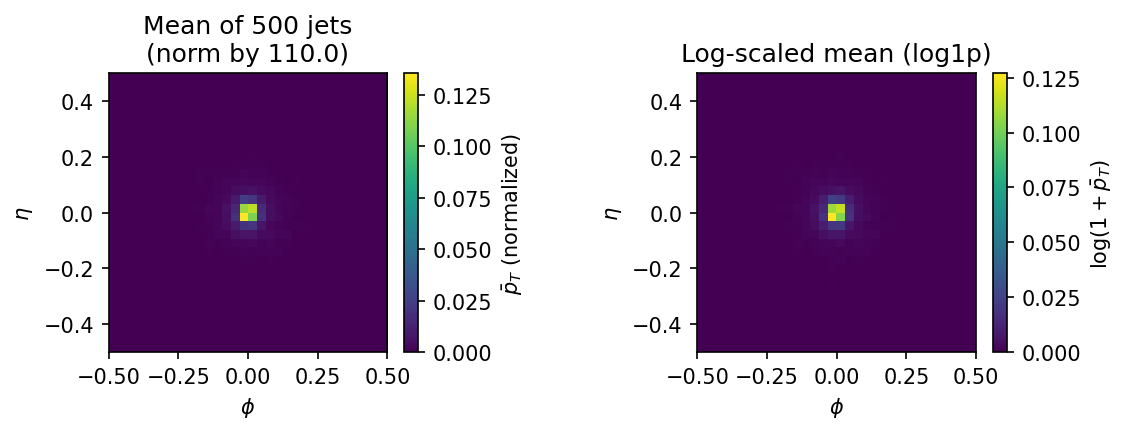

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3), dpi=150)

phi_min, phi_max = PHI_RANGE
eta_min, eta_max = ETA_RANGE

# Linear mean image
ax = axes[0]
im0 = ax.imshow(
    mean_img.T,
    origin="lower",
    extent=[phi_min, phi_max, eta_min, eta_max],
    # aspect="auto",
    # cmap="inferno",
    # interpolation="nearest",
)
ax.set_title(f"Mean of {N_AGG} jets\n(norm by {MAX_PT})")
ax.set_xlabel(r"$\phi$")
ax.set_ylabel(r"$\eta$")
fig.colorbar(im0, ax=ax, fraction=0.046, pad=0.04, label=r"$\bar{p}_T$ (normalized)")

# Log-scaled mean image
ax = axes[1]
im1 = ax.imshow(
    log_mean_img.T,
    origin="lower",
    extent=[phi_min, phi_max, eta_min, eta_max],
    # aspect="auto",
    # cmap="inferno",
    # interpolation="nearest",
)
ax.set_title("Log-scaled mean (log1p)")
ax.set_xlabel(r"$\phi$")
ax.set_ylabel(r"$\eta$")
fig.colorbar(im1, ax=ax, fraction=0.046, pad=0.04, label=r"$\log(1+\bar{p}_T)$")

plt.tight_layout()
plt.show()


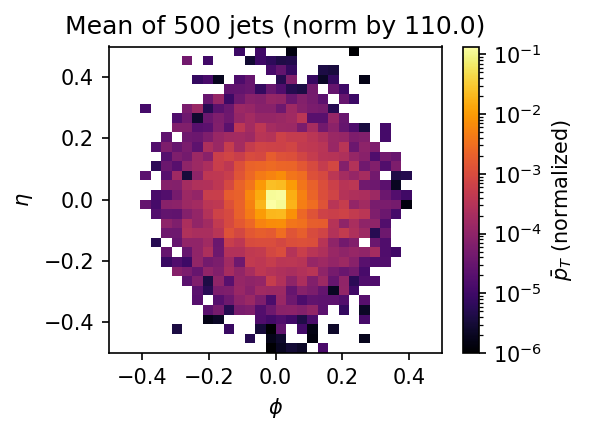

In [12]:
from matplotlib import colors
import numpy as np

phi_min, phi_max = PHI_RANGE
eta_min, eta_max = ETA_RANGE

# Use the normalized mean image
data = np.ma.masked_where(mean_img <= 0, mean_img)

if np.any(data > 0):
    vmin = max(data[data > 0].min(), 1e-6)
    vmax = data.max()
else:
    vmin, vmax = 1e-6, 1.0

use_log_norm = True  # or True if you want log color scaling
if use_log_norm:
    norm = colors.LogNorm(vmin=vmin, vmax=vmax)
else:
    norm = colors.Normalize(vmin=vmin, vmax=vmax)

fig, ax = plt.subplots(figsize=(4, 3), dpi=150)

im = ax.imshow(
    data.T,
    origin="lower",
    extent=[phi_min, phi_max, eta_min, eta_max],
    aspect="auto",
    cmap="inferno",
    interpolation="nearest",
    norm=norm,  # <- key change
)

ax.set_title(f"Mean of {N_AGG} jets (norm by {MAX_PT})")
ax.set_xlabel(r"$\phi$")
ax.set_ylabel(r"$\eta$")
cbar = fig.colorbar(im, ax=ax)
cbar.set_label(r"$\bar{p}_T$ (normalized)")
plt.tight_layout()
plt.show()


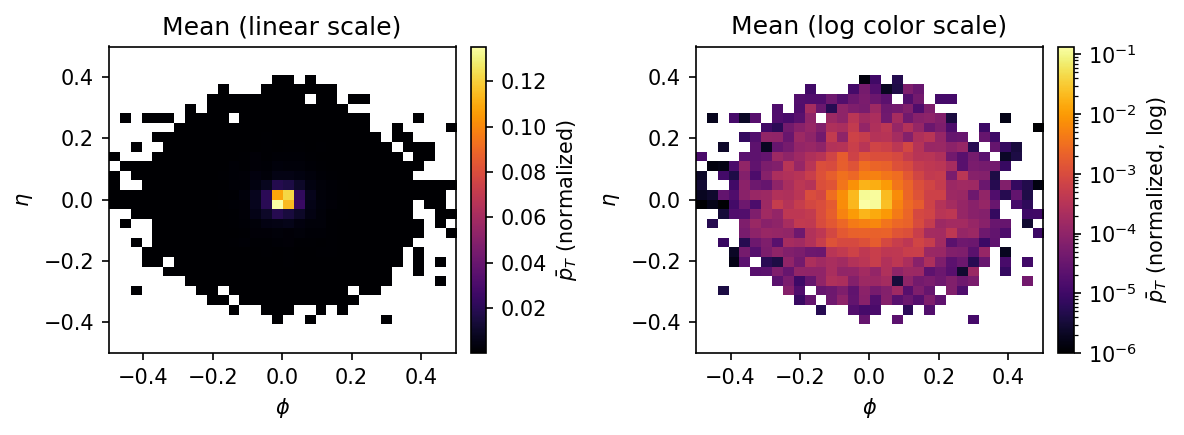

In [15]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors

phi_min, phi_max = PHI_RANGE
eta_min, eta_max = ETA_RANGE

# Mask non-positive values (needed for log scale)
data = np.ma.masked_where(mean_img <= 0, mean_img)

# Linear scale limits
vmin_lin = float(data.min()) if np.any(data > 0) else 0.0
vmax_lin = float(data.max()) if np.any(data > 0) else 1.0
norm_lin = colors.Normalize(vmin=vmin_lin, vmax=vmax_lin)

# Log scale limits (safe)
if np.any(data > 0):
    vmin_log = max(float(data[data > 0].min()), 1e-6)
    vmax_log = float(data.max())
else:
    vmin_log, vmax_log = 1e-6, 1.0
norm_log = colors.LogNorm(vmin=vmin_log, vmax=vmax_log)

fig, axes = plt.subplots(1, 2, figsize=(8, 3), dpi=150)

# --- Left: without log normalization (linear) ---
ax = axes[0]
im0 = ax.imshow(
    data,
    origin="lower",
    extent=[phi_min, phi_max, eta_min, eta_max],
    aspect="auto",
    cmap="inferno",
    interpolation="nearest",
    norm=norm_lin,
)
ax.set_title("Mean (linear scale)")
ax.set_xlabel(r"$\phi$")
ax.set_ylabel(r"$\eta$")
fig.colorbar(im0, ax=ax, fraction=0.046, pad=0.04, label=r"$\bar{p}_T$ (normalized)")

# --- Right: with log normalization ---
ax = axes[1]
im1 = ax.imshow(
    data,
    origin="lower",
    extent=[phi_min, phi_max, eta_min, eta_max],
    aspect="auto",
    cmap="inferno",
    interpolation="nearest",
    norm=norm_log,
)
ax.set_title("Mean (log color scale)")
ax.set_xlabel(r"$\phi$")
ax.set_ylabel(r"$\eta$")
fig.colorbar(im1, ax=ax, fraction=0.046, pad=0.04, label=r"$\bar{p}_T$ (normalized, log)")

plt.tight_layout()
plt.show()
